In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                                precision_recall_fscore_support)
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression


In [2]:
# World Population data
file_path_pop = "world_population.csv"
df_raw = pd.read_csv(file_path_pop)

# Calculate population thresholds
thresholds = df_raw["2022 Population"].quantile([1/3, 2/3])


def classify_population(pop, low_thresh, high_thresh):
    if pop < low_thresh:
        return "Low"
    elif pop < high_thresh:
        return "Medium"
    else:
        return "High"


# Create population class
df_raw["Pop_class"] = df_raw["2022 Population"].apply(
    classify_population,
    low_thresh=thresholds[1/3],
    high_thresh=thresholds[2/3]
)


# Detect column names
area_col = (
    "Area (km²)"
    if "Area (km²)" in df_raw.columns
    else "Area (km2)"
)

density_col = (
    "Density (per km²)"
    if "Density (per km²)" in df_raw.columns
    else "Density (per km2)"
)


# Select features
feature_cols = [
    "1970 Population",
    "1980 Population",
    "1990 Population",
    "2000 Population",
    "2010 Population",
    "2015 Population",
    "2020 Population",
    area_col,
    density_col,
    "Growth Rate",
    "World Population Percentage"
]


# Create modelling DataFrame
df_pop = df_raw[
    feature_cols + ["Pop_class"]
].dropna().copy()


# Encode target
le = LabelEncoder()

df_pop["Pop_class_encoded"] = le.fit_transform(
    df_pop["Pop_class"]
)


print(f"Population DataFrame shape: {df_pop.shape}")
print(
    f"Class distribution:\n"
    f"{df_pop['Pop_class'].value_counts()}"
)

Population DataFrame shape: (234, 13)
Class distribution:
Pop_class
High      78
Medium    78
Low       78
Name: count, dtype: int64


## __Challenge 1: Training a Random Forest__

A Random Forest grows many Decision Trees — each on a bootstrap sample of the training data and using only a random subset of features at each split. The ensemble votes on the final prediction. This reduces the variance of a single tree without substantially increasing bias.

### __Task__
Create a function named `train_random_forest` that:
- Takes a DataFrame, feature columns, the encoded target column name, `n_estimators` (default `100`), `max_depth` (default `None`), and `random_state` (default `42`).
- Splits the data 80-20 using `random_state`.
- Trains a `RandomForestClassifier` with the given parameters.
- Returns `(model, X_test, y_test)`.


In [3]:
def train_random_forest(df, feature_cols, target_col, n_estimators=100, max_depth=None, random_state=42):
    # Insert your code here
    # Select features and target
    X = df[feature_cols]
    y = df[target_col]

    # Split data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=random_state
    )

    # Create Random Forest classifier
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        random_state=random_state
    )

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred = model.predict(X_test)

    # Calculate test accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Display results
    print(f"Number of estimators: {n_estimators}")
    print(f"Test set size: {len(X_test)}")
    print(f"Random Forest test accuracy: {accuracy:.4f}")

    return model, X_test, y_test

In [4]:
model, X_test, y_test = train_random_forest(
    df=df_pop,
    feature_cols=feature_cols,
    target_col="Pop_class_encoded",
    n_estimators=100,
    max_depth=None,
    random_state=42
)

Number of estimators: 100
Test set size: 47
Random Forest test accuracy: 1.0000


### __Task__
Create a function named `plot_feature_importance` that:
- Takes the fitted Random Forest model and the list of feature column names.
- Creates a horizontal bar chart of feature importances, sorted from highest to lowest.
- Returns a `pd.Series` of feature importances indexed by feature name, sorted in descending order.

**Note:** Use `model.feature_importances_` to access importances.

In [14]:
import seaborn as sns
def style_plot(
    ax,
    title=None,
    xlabel=None,
    ylabel=None,
    figsize=None,
    grid=True,
    remove_spine=True,
    spine_width=1.2,
    label_fontsize=11,
    title_fontsize=13
):
    if figsize:
        ax.figure.set_size_inches(*figsize)

    if xlabel:
        ax.set_xlabel(xlabel, fontsize=label_fontsize)

    if ylabel:
        ax.set_ylabel(ylabel, fontsize=label_fontsize)

    if title:
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold"
        )

    if grid:
        ax.grid(alpha=0.2, linestyle = '-', color = '0.75')

    if remove_spine:
        sns.despine(ax=ax, top=True, right=True)

    # Set spine width
    for spine in ax.spines.values():
        spine.set_linewidth(spine_width)

    return ax

In [15]:
def plot_feature_importance(model, feature_cols):
    # Get feature importances
        importances = pd.Series(
            model.feature_importances_,
            index=feature_cols
        )

        # Sort from highest to lowest
        importances = importances.sort_values(
            ascending=False
        )

        # Create horizontal bar chart
        fig, ax = plt.subplots(figsize=(8, 5))

        importances.sort_values().plot(
            kind="barh",
            ax=ax
        )

        style_plot(
            ax,
            title="Random Forest Feature Importance",
            xlabel="Importance",
            ylabel="Feature"
        )

        plt.tight_layout()
        plt.show()

        return importances

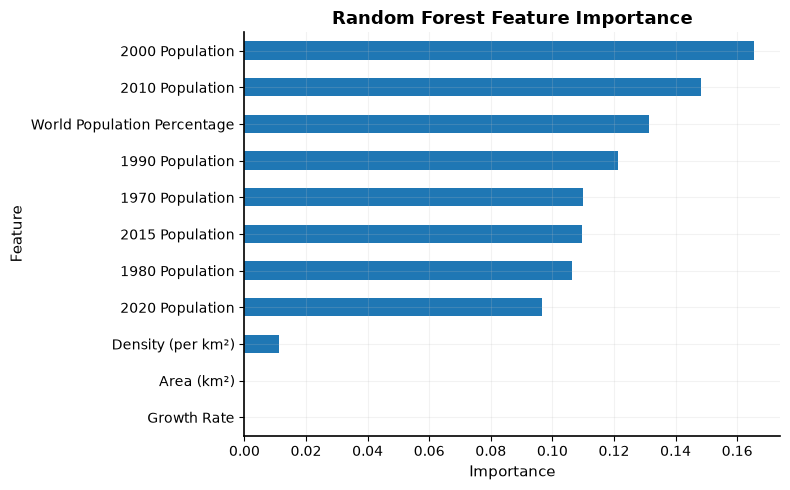

2000 Population                0.165620
2010 Population                0.148158
World Population Percentage    0.131334
1990 Population                0.121409
1970 Population                0.110047
2015 Population                0.109577
1980 Population                0.106304
2020 Population                0.096475
Density (per km²)              0.011078
Area (km²)                     0.000000
Growth Rate                    0.000000
dtype: float64

In [16]:
feature_importance = plot_feature_importance(
    model,
    feature_cols
)

display(feature_importance)

In [17]:
# Get the top 5
print("Top 5 features:")
display(feature_importance.head(5))

Top 5 features:


2000 Population                0.165620
2010 Population                0.148158
World Population Percentage    0.131334
1990 Population                0.121409
1970 Population                0.110047
dtype: float64

## **Challenge 3: Stability Comparison — Single Tree vs. Random Forest**

A core claim about ensemble methods is that they are **more stable** than a single model. We can test this directly: train both models 30 times with different random seeds, and compare how much their test accuracy varies across the runs.

### **Task**
Create a function named `stability_comparison` that:
- Takes a DataFrame, feature columns, target column, and a list of random seeds.
- For each seed: trains a `DecisionTreeClassifier` (`max_depth=5`) and a `RandomForestClassifier` (`n_estimators=100`) on an 80-20 split; records test accuracy for each.
- Plots a box plot comparing the accuracy distributions of the two models.
- Returns a DataFrame with columns `seed`, `dt_accuracy`, and `rf_accuracy`.


In [27]:
def stability_comparison(df, feature_cols, target_col, seeds):
    # Store results from each run
    results = []

    # Separate features and target
    X = df[feature_cols]
    y = df[target_col]

    # Train models for each random seed
    for seed in seeds:

        # 80-20 train-test split
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.20,
            random_state=seed
        )

        # Decision Tree
        tree = DecisionTreeClassifier(
            max_depth=5,
            random_state=seed
        )

        tree.fit(X_train, y_train)

        dt_pred = tree.predict(X_test)

        dt_accuracy = accuracy_score(
            y_test,
            dt_pred
        )

        # Random Forest
        rf_model = RandomForestClassifier(
            n_estimators=100,
            random_state=seed
        )

        rf_model.fit(X_train, y_train)

        rf_pred = rf_model.predict(X_test)

        rf_accuracy = accuracy_score(
            y_test,
            rf_pred
        )

        # Store results
        results.append({
            "seed": seed,
            "dt_accuracy": dt_accuracy,
            "rf_accuracy": rf_accuracy
        })

    # Convert results to DataFrame
    results_df = pd.DataFrame(results)

    # Create box plot
    fig, ax = plt.subplots(figsize=(8, 5))

    results_df[
        ["dt_accuracy", "rf_accuracy"]
    ].plot(
        kind="box",
        ax=ax
    )

    style_plot(
        ax,
        title="Stability Comparison: Decision Tree vs Random Forest",
        xlabel="Model",
        ylabel="Test Accuracy"
    )

    ax.set_xticklabels([
        "Decision Tree",
        "Random Forest"
    ])

    plt.tight_layout()
    plt.show()

    return results_df


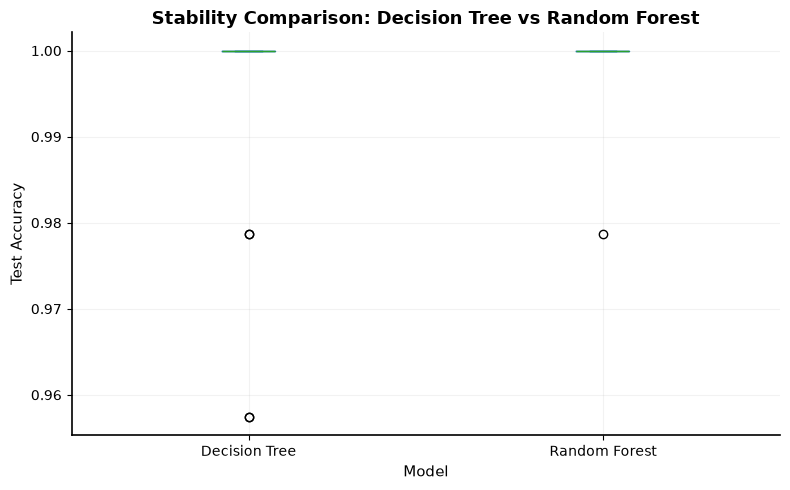

In [28]:
seeds = list(range(30))

stability_results = stability_comparison(
    df_pop,
    feature_cols,
    "Pop_class_encoded",
    seeds
)

In [29]:
display(
    stability_results[
        ["dt_accuracy", "rf_accuracy"]
    ].describe()
)

,dt_accuracy,rf_accuracy
count,30.000000,30.000000
mean,0.995745,0.999291
std,0.011720,0.003885
min,0.957447,0.978723
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,1.000000,1.000000


> Random Forest has a slightly higher mean accuracy and a substantially lower standard deviation, demonstrating both better average performance and greater stability across the 30 random seeds.

In [19]:
from sqlalchemy import create_engine, text

db_path = 'sqlite:///Maji_Ndogo_farm_survey_small.db'
engine = create_engine(db_path)

sql_query = """
SELECT *
FROM geographic_features
LEFT JOIN weather_features USING (Field_ID)
LEFT JOIN soil_and_crop_features USING (Field_ID)
LEFT JOIN farm_management_features USING (Field_ID)
"""

with engine.connect() as connection:
    MD_df = pd.read_sql_query(text(sql_query), connection)

# Standard cleaning pipeline from earlier in the programme
MD_df.rename(columns={'Annual_yield': 'Crop_type_Temp', 'Crop_type': 'Annual_yield'}, inplace=True)
MD_df.rename(columns={'Crop_type_Temp': 'Crop_type'}, inplace=True)
MD_df['Elevation'] = MD_df['Elevation'].abs()

def correct_crop_type(crop):
    corrections = {'cassaval': 'cassava', 'wheatn': 'wheat', 'teaa': 'tea'}
    return corrections.get(crop.strip(), crop.strip())

MD_df['Crop_type'] = MD_df['Crop_type'].apply(correct_crop_type)

# Engineer the binary target
MD_df['Heavily_Polluted'] = (MD_df['Pollution_level'] > 0.7).astype(int)

print(f'Maji Ndogo DataFrame shape: {MD_df.shape}')
print(f'Heavily Polluted distribution:\n{MD_df["Heavily_Polluted"].value_counts()}')

Maji Ndogo DataFrame shape: (5654, 19)
Heavily Polluted distribution:
Heavily_Polluted
0    5278
1     376
Name: count, dtype: int64


In [20]:
def train_logistic_binary(df, feature_cols):

    # Select features and target
    data = df[feature_cols + ["Heavily_Polluted"]].dropna()

    X = data[feature_cols]
    y = data["Heavily_Polluted"]

    # Split into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    # Create Logistic Regression model
    model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)

    print(f"Logistic Regression test accuracy: {accuracy:.4f}")
    print()
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    return model, X_test, y_test

In [21]:
audit_features = [
        'Elevation', 'Rainfall', 'Min_temperature_C', 'Max_temperature_C',
        'Ave_temps', 'Soil_fertility', 'pH', 'Slope', 'Plot_size'
]

In [22]:
logreg_model, X_test, y_test = train_logistic_binary(
    MD_df,
    audit_features
)

Logistic Regression test accuracy: 0.9381

              precision    recall  f1-score   support

           0       0.94      1.00      0.97      1061
           1       0.00      0.00      0.00        70

    accuracy                           0.94      1131
   macro avg       0.47      0.50      0.48      1131
weighted avg       0.88      0.94      0.91      1131



## __Challenge 5: Decision Boundary — Threshold Adjustment__

By default, Logistic Regression predicts the positive class if `P(Heavily_Polluted) >= 0.5`. But in a pollution audit, **missing a polluted field (False Negative) is more costly than a false alarm (False Positive)**. We can lower the threshold to catch more polluted fields — at the cost of flagging some clean fields incorrectly.

### __Task__
Create a function named `evaluate_threshold` that:
- Takes the fitted Logistic Regression model, `X_test`, `y_test`, and a `threshold` value (default `0.3`).
- Uses `model.predict_proba(X_test)[:, 1]` to get the probability of the positive class.
- Applies the threshold to produce binary predictions.
- Prints the full classification report.
- Returns a tuple `(precision, recall, f1)` for the **positive class** (label `1` — heavily polluted).

**Note:** Use `precision_recall_fscore_support` with `pos_label=1` and `average='binary'`.

In [24]:
def evaluate_threshold(
    model,
    X_test,
    y_test,
    threshold=0.3
):
    # Get probability of the positive class
    y_prob = model.predict_proba(X_test)[:, 1]

    # Apply the selected threshold
    y_pred = (y_prob >= threshold).astype(int)

    # Print classification report
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["Clean", "Heavily Polluted"],
            zero_division=0
        )
    )

    # Calculate positive-class metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        pos_label=1,
        average="binary",
        zero_division=0
    )

    print(
        f"Precision: {precision:.4f}, "
        f"Recall: {recall:.4f}, "
        f"F1: {f1:.4f}"
    )

    return precision, recall, f1

In [25]:
print("--- Default threshold (0.5) ---")

precision_05, recall_05, f1_05 = evaluate_threshold(
    logreg_model,
    X_test,
    y_test,
    threshold=0.5
)

--- Default threshold (0.5) ---
                  precision    recall  f1-score   support

           Clean       0.94      1.00      0.97      1061
Heavily Polluted       0.00      0.00      0.00        70

        accuracy                           0.94      1131
       macro avg       0.47      0.50      0.48      1131
    weighted avg       0.88      0.94      0.91      1131

Precision: 0.0000, Recall: 0.0000, F1: 0.0000


In [26]:
print("\n--- Audit threshold (0.3) ---")

precision_03, recall_03, f1_03 = evaluate_threshold(
    logreg_model,
    X_test,
    y_test,
    threshold=0.3
)


--- Audit threshold (0.3) ---
                  precision    recall  f1-score   support

           Clean       0.94      1.00      0.97      1061
Heavily Polluted       0.00      0.00      0.00        70

        accuracy                           0.94      1131
       macro avg       0.47      0.50      0.48      1131
    weighted avg       0.88      0.94      0.91      1131

Precision: 0.0000, Recall: 0.0000, F1: 0.0000


### __Business Interpretation:__ 
>The default 0.5 classification threshold prioritises the majority Clean class and fails to identify heavily polluted fields. Because false negatives are more costly in an environmental audit, a lower probability threshold should be considered. However, threshold reduction alone may not resolve the problem if the Logistic Regression model assigns very low probabilities to the polluted class. This suggests that the model's class imbalance and predictive separation should be investigated before selecting the final operating threshold.